# Homework 5 — DSCI 552
**Name:** Max (qzheng09@usc.edu)

Repository layout: this notebook lives in `notebook/`; the raw data files (`diagnosis.data/.names`,
`communities.data/.names`) are in `../data/`. Install dependencies with `pip install -r requirements.txt`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import mean_squared_error
import xgboost as xgb
from pathlib import Path
from IPython.display import display
RS = 552
np.random.seed(RS)
pd.set_option("display.width", 160); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 200); pd.set_option("display.max_colwidth", None)

# data folder is ../data relative to notebook/ (falls back to ./data if run from the HW root)
DATA = Path("../data") if Path("../data/diagnosis.data").exists() else Path("data")
print("Reading data from:", DATA.resolve())

Reading data from: /home/claude/hw5/HW5/data


## 1. Decision Trees as Interpretable Models
### (a) Load the Acute Inflammations data
The file is UTF‑16 encoded, tab separated, and uses a comma as the decimal mark for temperature.
Each row is one (simulated) patient described by a medical expert. What each column captures, per `diagnosis.names`:

| Column | Type | What it captures |
|---|---|---|
| `temperature` | numeric, 35–42 °C | Body temperature. Bladder inflammation usually raises it but rarely above 38 °C; nephritis starts with a sudden fever that can reach 40 °C, so this is the main feature separating the two diseases. |
| `nausea` | yes/no | Occurrence of nausea; listed as a frequent accompanying symptom of nephritis. |
| `lumbar_pain` | yes/no | Lower‑back (kidney‑area) pain; the hallmark symptom of nephritis of renal‑pelvis origin. |
| `urine_pushing` | yes/no | Continuous need to urinate; the hallmark symptom of bladder inflammation. |
| `micturition_pains` | yes/no | Pain while urinating; typical of bladder inflammation (and often also present with nephritis). |
| `burning_urethra` | yes/no | Burning of the urethra, itching or swelling of the urethra outlet; a lower‑urinary‑tract symptom. |
| `d1_bladder_inflammation` | label | Decision 1: acute inflammation of the urinary bladder. |
| `d2_nephritis` | label | Decision 2: acute nephritis of renal‑pelvis origin. |

In [2]:
cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains",
        "burning_urethra", "d1_bladder_inflammation", "d2_nephritis"]
acute = pd.read_csv(DATA / "diagnosis.data", sep="\t", header=None, names=cols,
                    encoding="utf-16", decimal=",")
for c in cols[1:]:
    acute[c] = (acute[c].str.strip() == "yes").astype(int)
X1 = acute[cols[:6]]
Y1 = acute[cols[6:]]
print("shape:", acute.shape, "| missing values:", acute.isna().sum().sum())
print("\nSummary of every column (for binary columns, mean = share of 'yes'):")
display(acute.describe().T.round(3))
print("Full data set (all 120 rows):")
display(acute)

shape: (120, 8) | missing values: 0

Summary of every column (for binary columns, mean = share of 'yes'):


,count,mean,std,min,25%,50%,75%,max
temperature,120.0,38.724,1.819,35.5,37.1,37.95,40.6,41.5
nausea,120.0,0.242,0.430,0.0,0.0,0.00,0.0,1.0
lumbar_pain,120.0,0.583,0.495,0.0,0.0,1.00,1.0,1.0
urine_pushing,120.0,0.667,0.473,0.0,0.0,1.00,1.0,1.0
micturition_pains,120.0,0.492,0.502,0.0,0.0,0.00,1.0,1.0
burning_urethra,120.0,0.417,0.495,0.0,0.0,0.00,1.0,1.0
d1_bladder_inflammation,120.0,0.492,0.502,0.0,0.0,0.00,1.0,1.0
d2_nephritis,120.0,0.417,0.495,0.0,0.0,0.00,1.0,1.0


Full data set (all 120 rows):


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,d1_bladder_inflammation,d2_nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0
5,36.0,0,1,0,0,0,0,0
6,36.2,0,0,1,1,1,1,0
7,36.2,0,1,0,0,0,0,0
8,36.3,0,0,1,1,1,1,0
9,36.6,0,0,1,1,1,1,0


### (b) Decision tree on the whole data set
The data is multi‑label (two binary diagnoses). Before choosing between **label powerset** (one class per
(d1, d2) combination) and **binary relevance** (one tree per label), I check the evidence: how the labels
co‑occur, and how the two approaches compare under the same 5‑fold CV.

In [3]:
print("Label co-occurrence (rows = d1 bladder, cols = d2 nephritis):")
display(pd.crosstab(acute.d1_bladder_inflammation, acute.d2_nephritis, margins=True))
phi = np.corrcoef(acute.d1_bladder_inflammation, acute.d2_nephritis)[0, 1]
print(f"phi correlation between the two labels = {phi:.3f}")

lp_map = {(0,0): "neither", (1,0): "bladder_only", (0,1): "nephritis_only", (1,1): "both"}
y_lp_tmp = Y1.apply(lambda r: lp_map[(r.iloc[0], r.iloc[1])], axis=1)

# same folds for both approaches; metric = exact match (both labels correct)
skf_cmp = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
lp_acc, br_acc, br_leaves = [], [], []
for tr, te in skf_cmp.split(X1, y_lp_tmp):
    lp = DecisionTreeClassifier(random_state=RS).fit(X1.iloc[tr], y_lp_tmp.iloc[tr])
    lp_acc.append((lp.predict(X1.iloc[te]) == y_lp_tmp.iloc[te]).mean())
    preds = np.column_stack([DecisionTreeClassifier(random_state=RS).fit(X1.iloc[tr], Y1.iloc[tr, j]).predict(X1.iloc[te])
                             for j in range(2)])
    br_acc.append((preds == Y1.iloc[te].values).all(axis=1).mean())
br_full = [DecisionTreeClassifier(random_state=RS).fit(X1, Y1.iloc[:, j]) for j in range(2)]
lp_full = DecisionTreeClassifier(random_state=RS).fit(X1, y_lp_tmp)
cmp = pd.DataFrame({
    "5-fold CV exact-match accuracy": [np.mean(lp_acc), np.mean(br_acc)],
    "number of trees": [1, 2],
    "total leaves (= number of rules)": [lp_full.get_n_leaves(), sum(t.get_n_leaves() for t in br_full)],
    "features used": [int((lp_full.feature_importances_ > 0).sum()),
                      int(((br_full[0].feature_importances_ + br_full[1].feature_importances_) > 0).sum())]},
    index=["Label powerset", "Binary relevance"])
display(cmp.round(4))

Label co-occurrence (rows = d1 bladder, cols = d2 nephritis):


d2_nephritis,0,1,All
d1_bladder_inflammation,,,
0,30,31,61
1,40,19,59
All,70,50,120


phi correlation between the two labels = -0.189


,5-fold CV exact-match accuracy,number of trees,total leaves (= number of rules),features used
Label powerset,0.9917,1,6,4
Binary relevance,1.0000,2,7,4


**Is label powerset more relevant here?** Only partly, and the evidence above shows why. The usual argument for label powerset is that it can exploit dependence between labels, but here the two diagnoses are only weakly (and negatively) related: φ = −0.19, and all four (d1, d2) combinations occur (30 / 31 / 40 / 19 patients). In accuracy, binary relevance is not worse: under the same 5 folds it reaches 1.000 exact-match CV accuracy versus 0.992 for label powerset (a difference of one misclassified patient out of 120). Label powerset is still the more relevant choice **for this assignment's goal, interpretability**: it gives a single tree with 6 rules whose conclusion is the complete diagnosis (e.g. "both"), whereas binary relevance needs two separate trees (7 leaves in total) that a reader has to combine by hand. Both use the same 4 features. I therefore use label powerset below, and I note that sklearn's native multi-output tree gives the same 6-leaf structure.

bladder_only      40
nephritis_only    31
neither           30
both              19
Name: count, dtype: int64
Training accuracy: 1.0 | depth: 4 | leaves: 6


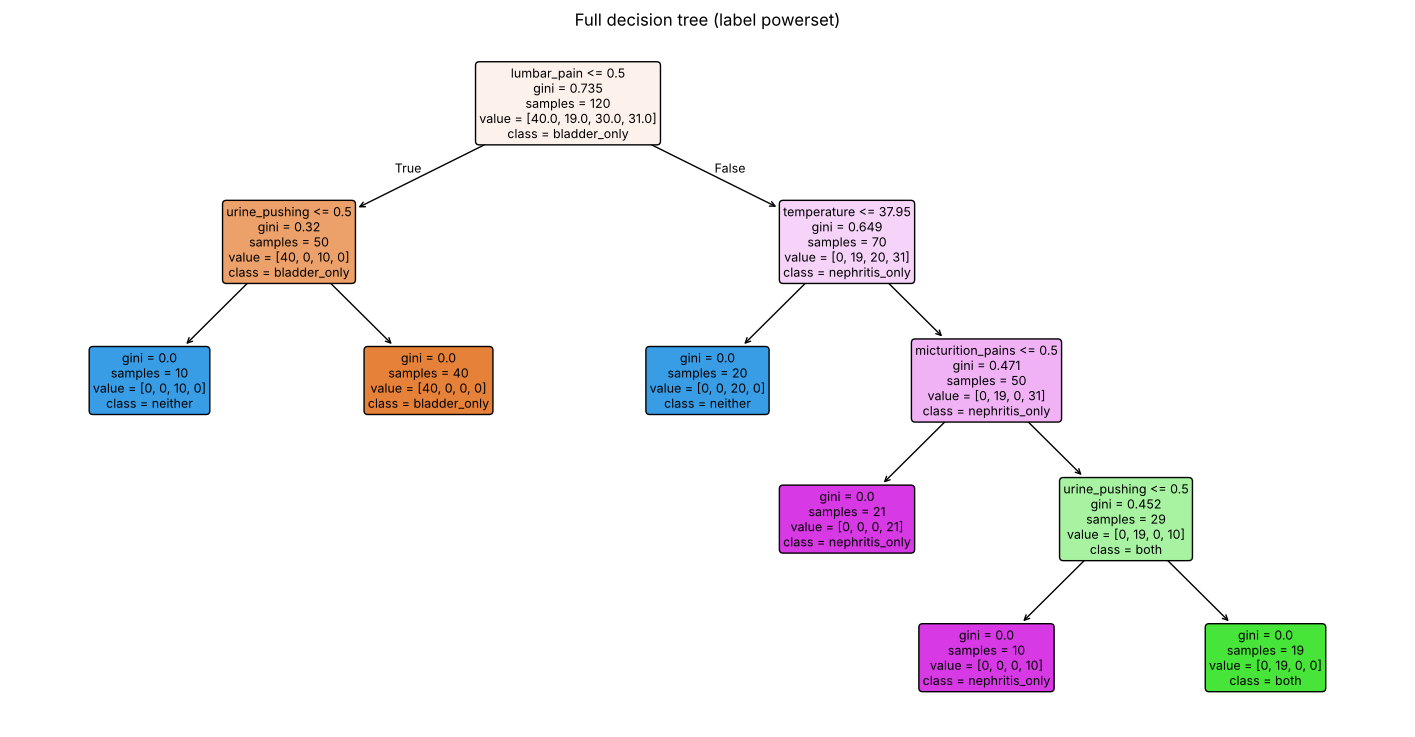

Native multi-output tree accuracy (exact match): 1.0 | leaves: 6


In [4]:
lp_map = {(0,0): "neither", (1,0): "bladder_only", (0,1): "nephritis_only", (1,1): "both"}
y_lp = Y1.apply(lambda r: lp_map[(r.iloc[0], r.iloc[1])], axis=1)
print(y_lp.value_counts())

tree_full = DecisionTreeClassifier(random_state=RS).fit(X1, y_lp)
print("Training accuracy:", tree_full.score(X1, y_lp),
      "| depth:", tree_full.get_depth(), "| leaves:", tree_full.get_n_leaves())

plt.figure(figsize=(18, 9))
plot_tree(tree_full, feature_names=X1.columns, class_names=tree_full.classes_,
          filled=True, rounded=True, fontsize=9)
plt.title("Full decision tree (label powerset)"); plt.show()

mo = DecisionTreeClassifier(random_state=RS).fit(X1, Y1)
print("Native multi-output tree accuracy (exact match):", (mo.predict(X1) == Y1.values).all(axis=1).mean(),
      "| leaves:", mo.get_n_leaves())

### (c) IF‑THEN rules
Adapted from the KDnuggets code: walk every root‑to‑leaf path and print its conditions. For binary features, `<= 0.5` means *no* and `> 0.5` means *yes*.

In [5]:
def tree_to_rules(tree, feature_names, class_names):
    t = tree.tree_
    fn = [feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined" for i in t.feature]
    binary = set(c for c in feature_names if c != "temperature")
    rules = []
    def cond(name, thr, left):
        if name in binary:
            return f"{name} = {'no' if left else 'yes'}"
        return f"{name} {'<=' if left else '>'} {thr:.2f}"
    def recurse(node, path):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, thr = fn[node], t.threshold[node]
            recurse(t.children_left[node],  path + [cond(name, thr, True)])
            recurse(t.children_right[node], path + [cond(name, thr, False)])
        else:
            v = t.value[node][0]
            cls = class_names[int(np.argmax(v))]
            n = int(t.n_node_samples[node])
            rules.append((path, cls, n))
    recurse(0, [])
    rules.sort(key=lambda r: -r[2])
    for i, (p, cls, n) in enumerate(rules, 1):
        print(f"Rule {i}: IF " + " AND ".join(p) + f"  THEN {cls}   (n={n})")
    return rules

rules_full = tree_to_rules(tree_full, list(X1.columns), tree_full.classes_)

Rule 1: IF lumbar_pain = no AND urine_pushing = yes  THEN bladder_only   (n=40)
Rule 2: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no  THEN nephritis_only   (n=21)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95  THEN neither   (n=20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes  THEN both   (n=19)
Rule 5: IF lumbar_pain = no AND urine_pushing = no  THEN neither   (n=10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no  THEN nephritis_only   (n=10)


**What the rules say.** The tree uses only 4 of the 6 features; nausea and burning of the urethra are never needed. The first split is on **lumbar pain**, the hallmark of nephritis. (i) Without lumbar pain (Rules 1 and 5), the patient never has nephritis, and **urine pushing** alone decides bladder inflammation: 40 patients with urine pushing are bladder-only, and the 10 without it are healthy. (ii) With lumbar pain, **temperature** splits at 37.95 °C, which matches the description in `diagnosis.names` that bladder inflammation rarely raises the temperature above 38 °C while nephritis starts with a high fever. All 20 patients with lumbar pain but no fever are healthy (Rule 3). (iii) Patients with lumbar pain and fever have nephritis (Rules 2, 4 and 6). They additionally have bladder inflammation ("both", Rule 4, 19 patients) only when they also show both bladder symptoms, **micturition pains and urine pushing**; with only one of them, or none, it is nephritis only (Rules 2 and 6, 31 patients). Every leaf is pure (Gini = 0), so each rule is 100% correct on the data.

### (d) Cost‑complexity pruning
Compute the pruning path (`ccp_alpha` values), then pick α by 5‑fold stratified cross‑validation.
Among all α whose CV accuracy is within one standard error of the best, I take the **largest** α
(the smallest tree), following the one‑standard‑error rule — this favors interpretability.

,alpha,cv_acc,se,leaves,fold accuracies
0,0.0000,0.9917,0.0083,6,"[0.958, 1.0, 1.0, 1.0, 1.0]"
1,0.0982,0.8583,0.0250,4,"[0.958, 0.833, 0.833, 0.833, 0.833]"
2,0.1333,0.7667,0.0312,3,"[0.833, 0.75, 0.75, 0.667, 0.833]"
3,0.1820,0.6750,0.0333,2,"[0.625, 0.75, 0.75, 0.667, 0.583]"
4,0.2229,0.4833,0.0612,1,"[0.333, 0.583, 0.583, 0.583, 0.333]"



Best CV accuracy = 0.9917; chosen alpha (1-SE rule) = 0.0000


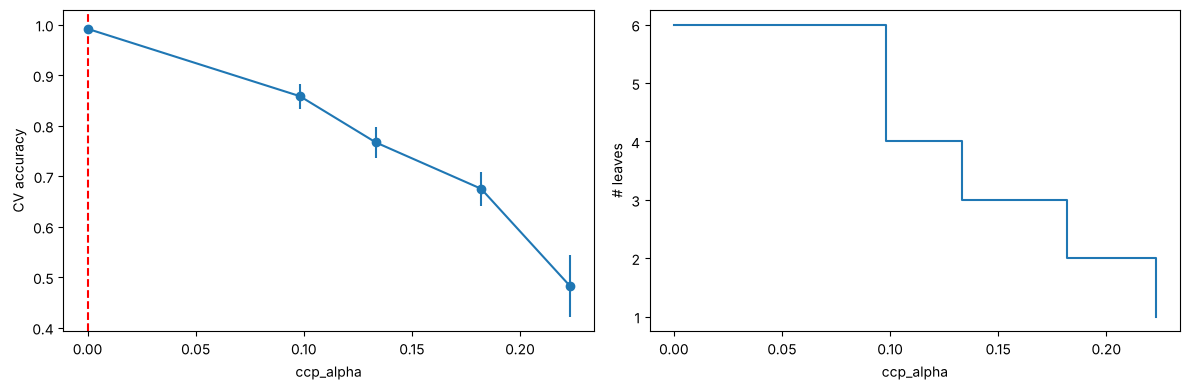

In [6]:
path = tree_full.cost_complexity_pruning_path(X1, y_lp)
alphas = np.unique(path.ccp_alphas)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
res = []
for a in alphas:
    m = DecisionTreeClassifier(random_state=RS, ccp_alpha=a)
    s = cross_val_score(m, X1, y_lp, cv=skf)
    leaves = DecisionTreeClassifier(random_state=RS, ccp_alpha=a).fit(X1, y_lp).get_n_leaves()
    res.append((a, s.mean(), s.std(ddof=1)/np.sqrt(len(s)), leaves, np.round(s, 3).tolist()))
ccp = pd.DataFrame(res, columns=["alpha", "cv_acc", "se", "leaves", "fold accuracies"])
display(ccp.round(4))

best = ccp.cv_acc.max()
se_best = ccp.loc[ccp.cv_acc.idxmax(), "se"]
alpha_star = ccp[ccp.cv_acc >= best - se_best].alpha.max()
print(f"\nBest CV accuracy = {best:.4f}; chosen alpha (1-SE rule) = {alpha_star:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].errorbar(ccp.alpha, ccp.cv_acc, yerr=ccp.se, marker="o"); ax[0].set_xlabel("ccp_alpha"); ax[0].set_ylabel("CV accuracy")
ax[0].axvline(alpha_star, ls="--", c="r")
ax[1].step(ccp.alpha, ccp.leaves, where="post"); ax[1].set_xlabel("ccp_alpha"); ax[1].set_ylabel("# leaves")
plt.tight_layout(); plt.show()

Pruned tree: depth 4 | leaves 6 | training accuracy 1.0


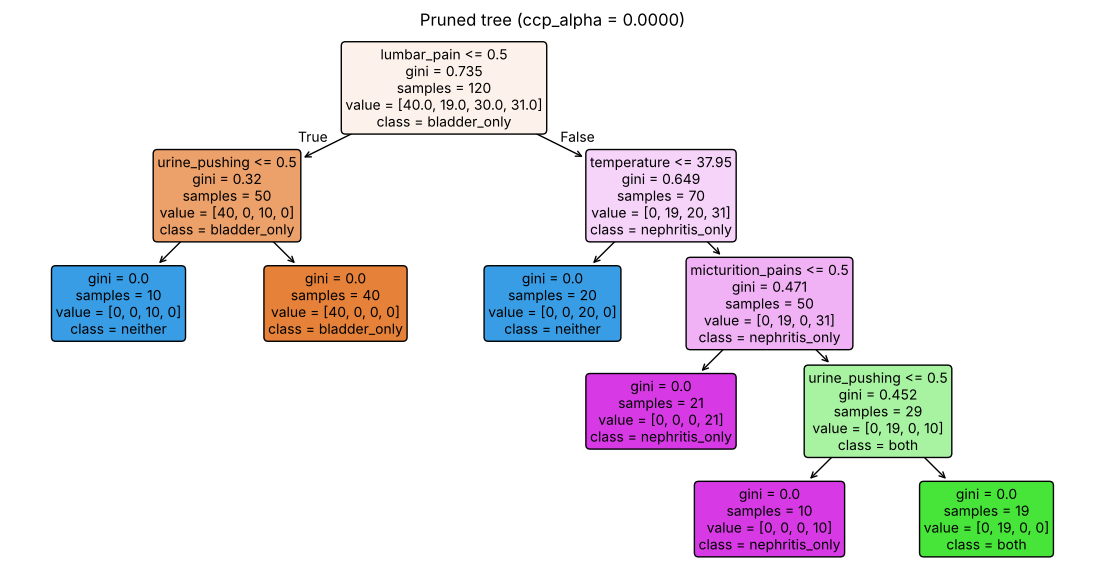

Rule 1: IF lumbar_pain = no AND urine_pushing = yes  THEN bladder_only   (n=40)
Rule 2: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no  THEN nephritis_only   (n=21)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95  THEN neither   (n=20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes  THEN both   (n=19)
Rule 5: IF lumbar_pain = no AND urine_pushing = no  THEN neither   (n=10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no  THEN nephritis_only   (n=10)


In [7]:
tree_pruned = DecisionTreeClassifier(random_state=RS, ccp_alpha=alpha_star).fit(X1, y_lp)
print("Pruned tree: depth", tree_pruned.get_depth(), "| leaves", tree_pruned.get_n_leaves(),
      "| training accuracy", round(tree_pruned.score(X1, y_lp), 4))
plt.figure(figsize=(14, 7))
plot_tree(tree_pruned, feature_names=X1.columns, class_names=tree_pruned.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title(f"Pruned tree (ccp_alpha = {alpha_star:.4f})"); plt.show()
rules_pruned = tree_to_rules(tree_pruned, list(X1.columns), tree_pruned.classes_)

For comparison, the next step on the pruning path (the largest α that still keeps 4 leaves) gives an even simpler rule set, at a cost in accuracy:

ccp_alpha = 0.0982 | leaves 4 | training accuracy 0.8417


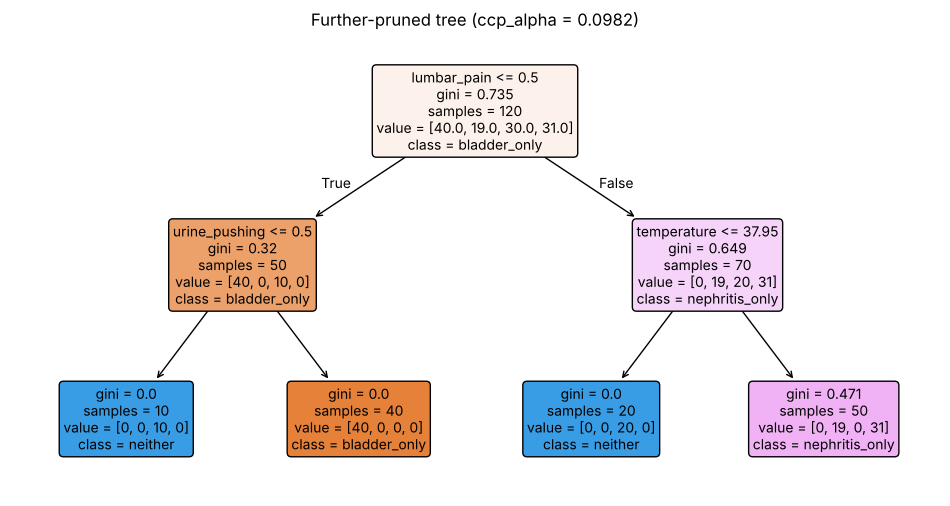

Rule 1: IF lumbar_pain = yes AND temperature > 37.95  THEN nephritis_only   (n=50)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes  THEN bladder_only   (n=40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95  THEN neither   (n=20)
Rule 4: IF lumbar_pain = no AND urine_pushing = no  THEN neither   (n=10)


In [8]:
alpha_4 = ccp[ccp.leaves == 4].alpha.max()
tree_4 = DecisionTreeClassifier(random_state=RS, ccp_alpha=alpha_4).fit(X1, y_lp)
print(f"ccp_alpha = {alpha_4:.4f} | leaves {tree_4.get_n_leaves()} | training accuracy {tree_4.score(X1, y_lp):.4f}")
plt.figure(figsize=(12, 6))
plot_tree(tree_4, feature_names=X1.columns, class_names=tree_4.classes_, filled=True, rounded=True, fontsize=10)
plt.title(f"Further-pruned tree (ccp_alpha = {alpha_4:.4f})"); plt.show()
_ = tree_to_rules(tree_4, list(X1.columns), tree_4.classes_)

**Discussion.** The cost-complexity path has only five subtrees (6, 4, 3, 2 and 1 leaves). The unpruned 6-leaf tree has the best 5-fold CV accuracy, 0.992 ± 0.008 (SE): it is perfect on four folds and makes one error on the fifth. The next subtree (4 leaves, α ≈ 0.098) drops to 0.858 ± 0.025, i.e. to 0.833 on four of the five folds. That is about 16 standard errors below the best, so it is far outside the one-SE band, and the 1-SE rule selects α = 0. **The minimal tree that keeps (near-)perfect accuracy is therefore the 6-leaf, depth-4 tree itself, with the 6 IF-THEN rules above.** It is already small: 4 features, at most 4 conditions per rule, and 6 rules. If we accept lower accuracy for an even shorter rule set, the 4-leaf tree reduces to rules of two conditions each: lumbar pain + fever (> 37.95 °C) ⇒ nephritis; no lumbar pain + urine pushing ⇒ bladder inflammation; otherwise neither. However, it can no longer predict the *both* class, because those 19 patients are folded into "nephritis only", so training accuracy falls to 0.842. Because the CV evidence shows a large accuracy loss for only 2 fewer rules, I recommend the 6-leaf tree as the final interpretable model.

## 2. The LASSO and Boosting for Regression
### (a) Load the Communities and Crime data
128 columns; the target is `ViolentCrimesPerPop`. Missing values are coded as `?`.
First 1495 rows → training set, rest → test set.

In [9]:
import re
names, DESC = [], {}
with open(DATA / "communities.names") as f:
    for line in f:
        if line.startswith("@attribute"):
            names.append(line.split()[1])
        m = re.match(r"--\s*(\w+):\s*(.*)", line)
        if m:   # the attribute descriptions in the .names file, used to explain every variable we list
            DESC[m.group(1)] = re.sub(r"\s*\((numeric - decimal|numeric - expected to be integer|numeric|nominal|string)\)\s*$", "", m.group(2).strip())

def describe_vars(cols, extra=None):
    """Table of variables with their meaning from communities.names (plus optional extra columns)."""
    out = pd.DataFrame({"meaning": [DESC.get(c, "") for c in cols]}, index=cols)
    if extra is not None:
        out = pd.concat([extra.loc[cols].to_frame() if isinstance(extra, pd.Series) else extra.loc[cols], out], axis=1)
    return out

crime = pd.read_csv(DATA / "communities.data", header=None, names=names, na_values="?")
print("shape:", crime.shape)
train_raw, test_raw = crime.iloc[:1495].copy(), crime.iloc[1495:].copy()
print("train", train_raw.shape, "| test", test_raw.shape)
print("\nTarget:", "ViolentCrimesPerPop =", DESC["ViolentCrimesPerPop"])
display(crime["ViolentCrimesPerPop"].describe().to_frame().T.round(3))
print("Non-predictive columns and their meaning:")
display(describe_vars(["state", "county", "community", "communityname", "fold"]))

shape: (1994, 128)
train (1495, 128) | test (499, 128)

Target: ViolentCrimesPerPop = total number of violent crimes per 100K popuation (numeric - decimal) GOAL attribute (to be predicted)


,count,mean,std,min,25%,50%,75%,max
ViolentCrimesPerPop,1994.0,0.238,0.233,0.0,0.07,0.15,0.33,1.0


Non-predictive columns and their meaning:


,meaning
state,"US state (by number) - not counted as predictive above, but if considered, should be consided nominal"
county,"numeric code for county - not predictive, and many missing values"
community,numeric code for community - not predictive and many missing values
communityname,community name - not predictive - for information only
fold,"fold number for non-random 10 fold cross validation, potentially useful for debugging, paired tests - not predictive"


### (b) Remove non‑predictive features and impute missing values
The description lists 5 non‑predictive attributes: `state`, `county`, `community`, `communityname`, `fold`; they are dropped.
For the remaining missing values, I first look at *where* they are and *how the affected columns are distributed*,
and choose the imputation method from that evidence (cells below). The imputer is fit on the training set only and then applied to the test set, to avoid leakage.

In [10]:
nonpred = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"
feats = [c for c in names if c not in nonpred + [target]]
print("number of predictive features:", len(feats))

miss = train_raw[feats].isna().sum()
miss_cols = miss[miss > 0].index.tolist()
print(f"{len(miss_cols)} features have missing values in the training set:")
display(describe_vars(miss_cols, pd.DataFrame({"n_missing": miss[miss_cols],
                                               "% missing": (100 * miss[miss_cols] / len(train_raw)).round(1)})))

police = [c for c in miss_cols if miss[c] > 100]
same_rows = train_raw[police].isna().all(axis=1).sum() == train_raw[police].isna().any(axis=1).sum()
print(f"The {len(police)} police (LEMAS) variables are missing on exactly the same rows: {same_rows}")

# evidence for choosing mean vs median: skewness and mean-median gap of the observed values
obs = train_raw[miss_cols]
ev = pd.DataFrame({"skewness": obs.skew(), "mean": obs.mean(), "median": obs.median()})
ev["mean - median"] = ev["mean"] - ev["median"]
ev["gap / std"] = ev["mean - median"] / obs.std()
display(ev.round(3).sort_values("skewness", ascending=False))
print(f"{(ev.skewness.abs() > 1).sum()} of {len(ev)} columns have |skewness| > 1; median of skewness = {ev.skewness.median():.2f}")

number of predictive features: 122
23 features have missing values in the training set:


,n_missing,% missing,meaning
OtherPerCap,1,0.1,per capita income for people with 'other' heritage
LemasSwornFT,1256,84.0,number of sworn full time police officers
LemasSwFTPerPop,1256,84.0,sworn full time police officers per 100K population
LemasSwFTFieldOps,1256,84.0,number of sworn full time police officers in field operations (on the street as opposed to administrative etc)
LemasSwFTFieldPerPop,1256,84.0,sworn full time police officers in field operations (on the street as opposed to administrative etc) per 100K population
LemasTotalReq,1256,84.0,total requests for police
LemasTotReqPerPop,1256,84.0,total requests for police per 100K popuation
PolicReqPerOffic,1256,84.0,total requests for police per police officer
PolicPerPop,1256,84.0,police officers per 100K population
RacialMatchCommPol,1256,84.0,a measure of the racial match between the community and the police force. High values indicate proportions in community and police force are similar


The 22 police (LEMAS) variables are missing on exactly the same rows: True


,skewness,mean,median,mean - median,gap / std
OfficAssgnDrugUnits,5.304,0.077,0.04,0.037,0.284
LemasSwornFT,4.394,0.075,0.02,0.055,0.356
PolicOperBudg,4.046,0.081,0.03,0.051,0.337
LemasTotalReq,3.535,0.101,0.04,0.061,0.353
PolicBudgPerPop,3.229,0.191,0.15,0.041,0.262
PolicPerPop,2.925,0.215,0.18,0.035,0.222
LemasSwFTPerPop,2.925,0.215,0.18,0.035,0.222
PctPolicAsian,2.772,0.102,0.00,0.102,0.496
LemasTotReqPerPop,2.595,0.214,0.17,0.044,0.264
LemasSwFTFieldPerPop,2.549,0.245,0.21,0.035,0.233


20 of 23 columns have |skewness| > 1; median of skewness = 2.31


**Choice of imputation.** The table shows two different situations. (1) 22 of the 23 incomplete columns are the police (LEMAS) variables. They are missing for the same 1,256 training communities (84%), because LEMAS only surveyed police departments with 100 or more officers. (2) `OtherPerCap` is missing in a single row. For the choice between mean and median, the evidence is the shape of the observed values: 20 of the 23 columns have |skewness| > 1 (median skewness 2.31), and for the most skewed ones the mean sits far above the median. For example, `PctPolicAsian` has mean 0.102 and median 0.00, a gap of half a standard deviation, and `LemasSwornFT` has mean 0.075 and median 0.02. With this much right skew, the mean is pulled by a few large departments and is not a typical value, so I impute with the **training-set median**, which is robust to those outliers. A limitation, visible later in part (e), is that after imputation 84% of rows share one value for each police variable. These features therefore carry little information, which is consistent with LASSO setting 9 of the 22 to exactly zero in part (h).

In [11]:
imp = SimpleImputer(strategy="median").fit(train_raw[feats])
Xtr = pd.DataFrame(imp.transform(train_raw[feats]), columns=feats)
Xte = pd.DataFrame(imp.transform(test_raw[feats]), columns=feats)
ytr = train_raw[target].values
yte = test_raw[target].values
print("Any NaN left:", Xtr.isna().any().any(), Xte.isna().any().any())

Any NaN left: False False


### (c) Correlation matrix

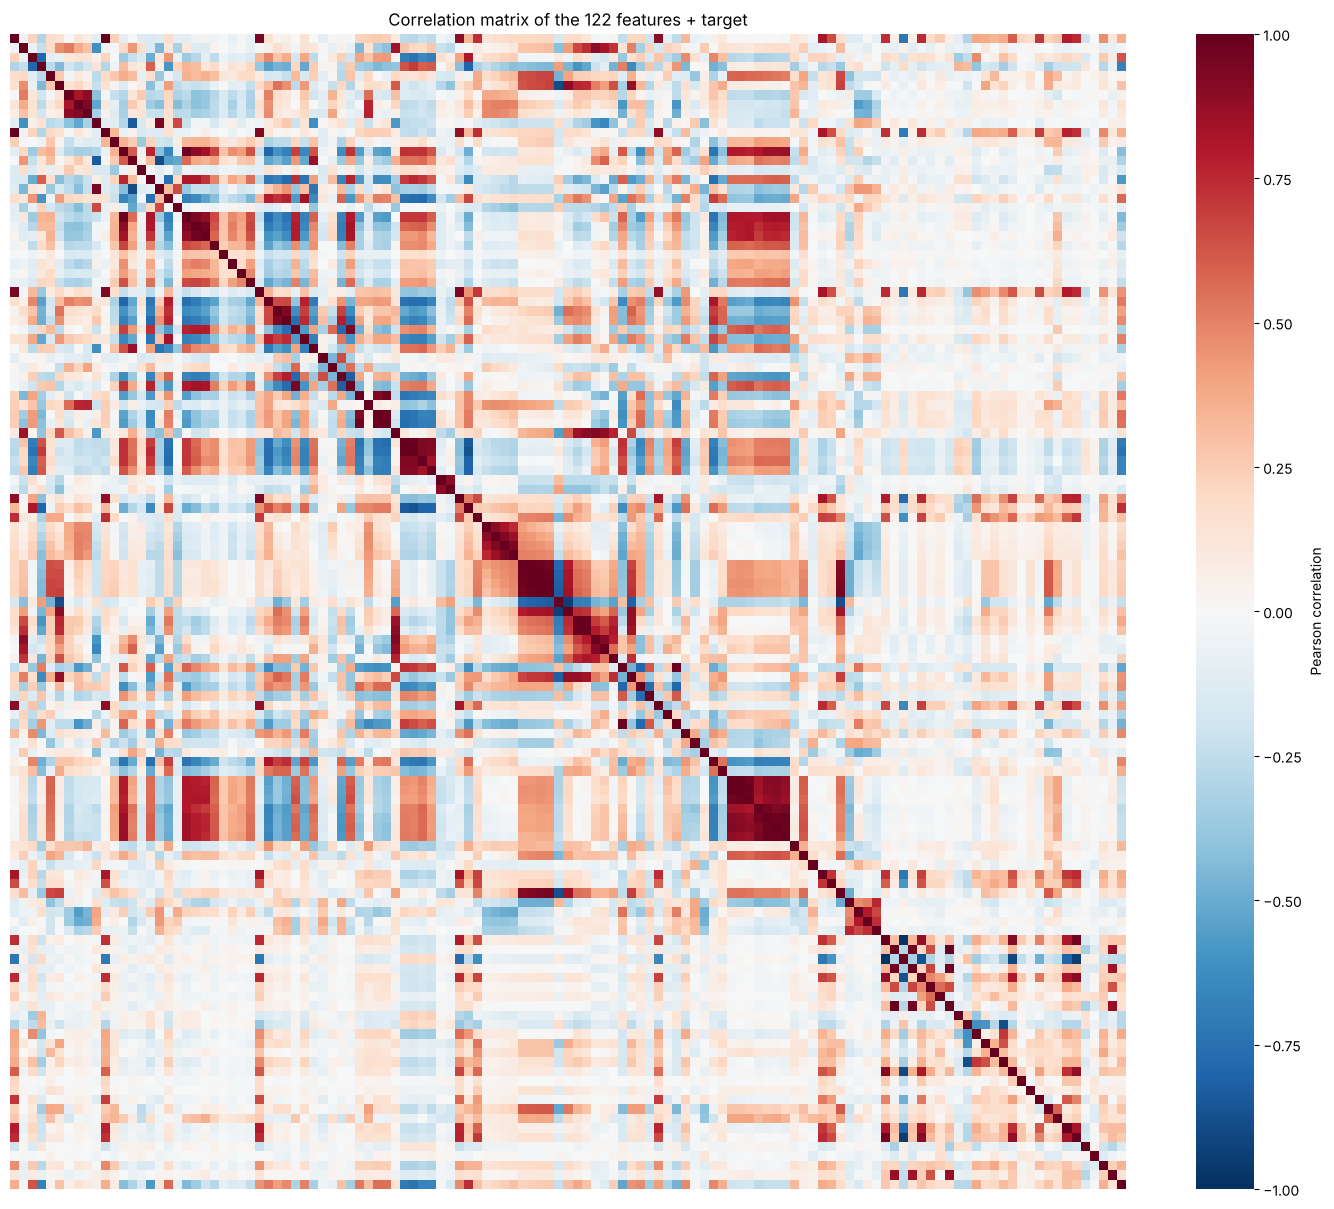

Features most correlated with the target:


,corr with target,meaning
PctKids2Par,-0.738,percentage of kids in family housing with two parents
PctIlleg,0.738,percentage of kids born to never married
PctFam2Par,-0.707,percentage of families (with kids) that are headed by two parents
racePctWhite,-0.685,percentage of population that is caucasian
PctYoungKids2Par,-0.666,percent of kids 4 and under in two parent households
PctTeen2Par,-0.662,percent of kids age 12-17 in two parent households
racepctblack,0.631,percentage of population that is african american
pctWInvInc,-0.576,percentage of households with investment / rent income in 1989
pctWPubAsst,0.575,percentage of households with public assistance income in 1989
FemalePctDiv,0.556,percentage of females who are divorced


Feature pairs with |r| > 0.9: 58 of 7381
Ten most correlated feature pairs:


,,|r|
LemasSwFTPerPop,PolicPerPop,1.000
PctRecImmig8,PctRecImmig10,0.996
OwnOccLowQuart,OwnOccMedVal,0.994
PctRecImmig5,PctRecImmig8,0.993
population,numbUrban,0.993
LemasSwornFT,LemasSwFTFieldOps,0.992
OwnOccMedVal,OwnOccHiQuart,0.991
PctRecentImmig,PctRecImmig5,0.989
RentMedian,MedRent,0.989
PctRecImmig5,PctRecImmig10,0.986


In [12]:
full_imp = pd.concat([Xtr, Xte]); full_imp[target] = np.r_[ytr, yte]
corr = full_imp.corr()
plt.figure(figsize=(18, 15))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, xticklabels=False, yticklabels=False,
            cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation matrix of the 122 features + target"); plt.show()
tc = corr[target].drop(target)
top_t = tc.abs().sort_values(ascending=False).index[:10]
print("Features most correlated with the target:")
display(describe_vars(top_t, tc.rename("corr with target").round(3)))

up = corr.drop(index=target, columns=target).where(np.triu(np.ones((len(feats), len(feats)), bool), 1)).stack().dropna()
print(f"Feature pairs with |r| > 0.9: {(up.abs() > 0.9).sum()} of {len(up)}")
print("Ten most correlated feature pairs:")
display(up.abs().sort_values(ascending=False).head(10).round(3).to_frame("|r|"))

**What the correlation matrix shows.** Two things stand out. (1) **Strong multicollinearity.** 58 of the 7,381 feature pairs have |r| > 0.9. Many are near-duplicates by construction: officers per 100K appears twice (`LemasSwFTPerPop`, `PolicPerPop`, r = 1.000), the recent-immigration windows (`PctRecImmig5/8/10`, r ≈ 0.99) are nested, house-value quartiles track the median (r ≈ 0.99), and `population` tracks `numbUrban` (r = 0.993). This makes the least-squares coefficients unstable and is the main motivation for ridge, LASSO and PCR in parts (g)–(i). (2) **The target is most correlated with family-structure variables**: the share of kids in two-parent households (`PctKids2Par`, r = −0.74), kids born to never-married parents (`PctIlleg`, +0.74), two-parent families (`PctFam2Par`, −0.71), followed by racial composition and income-source variables (public assistance +0.58, investment income −0.58). These same variables reappear as the most important features in the LASSO and XGBoost models.

### (d) Coefficient of variation CV = s / m
Computed on all rows (after imputation).

In [13]:
X_all = pd.concat([Xtr, Xte])
cv_vals = (X_all.std(ddof=1) / X_all.mean()).sort_values(ascending=False)
print("CV of all 122 features, sorted (with each feature's meaning):")
display(describe_vars(cv_vals.index, cv_vals.rename("CV").round(4)))

CV of all 122 features, sorted (with each feature's meaning):


,CV,meaning
PctPolicAsian,5.4478,percent of police that are asian
NumStreet,4.4077,number of homeless people counted in the street
NumInShelters,3.4855,number of people in homeless shelters
NumIlleg,2.9942,number of kids born to never married
NumImmig,2.9005,total number of people known to be foreign born
LemasPctOfficDrugUn,2.5553,percent of officers assigned to drug units
NumUnderPov,2.3050,number of people under the poverty level
population,2.2035,population for community:
LemasSwornFT,2.0807,number of sworn full time police officers
numbUrban,2.0017,number of people living in areas classified as urban


**Interpretation.** All features are normalized to [0, 1], so CV mostly reflects **how right-skewed a feature is**: CV is large when the mean is close to 0 and a few communities have large values. The top of the list is therefore made of (a) **raw counts** that scale with city size, such as homeless people in the street or in shelters, kids born to never-married parents, immigrants, people in poverty, population, urban population and vacant households, and (b) **police variables** that are almost constant after imputation. An example is `PctPolicAsian`, where 93% of values equal the median, so its huge CV of 5.4 is driven by a handful of departments. Percentage and per-capita features, such as household size or the share of people with a high-school education, have much lower CV. A high CV means a feature varies a lot relative to its average, not that it is related to the target; part (e) checks this directly.

### (e) Top ⌊√128⌋ = 11 features by CV: scatter plots and box plots

k = 11


,CV,meaning
PctPolicAsian,5.448,percent of police that are asian
NumStreet,4.408,number of homeless people counted in the street
NumInShelters,3.485,number of people in homeless shelters
NumIlleg,2.994,number of kids born to never married
NumImmig,2.900,total number of people known to be foreign born
LemasPctOfficDrugUn,2.555,percent of officers assigned to drug units
NumUnderPov,2.305,number of people under the poverty level
population,2.204,population for community:
LemasSwornFT,2.081,number of sworn full time police officers
numbUrban,2.002,number of people living in areas classified as urban


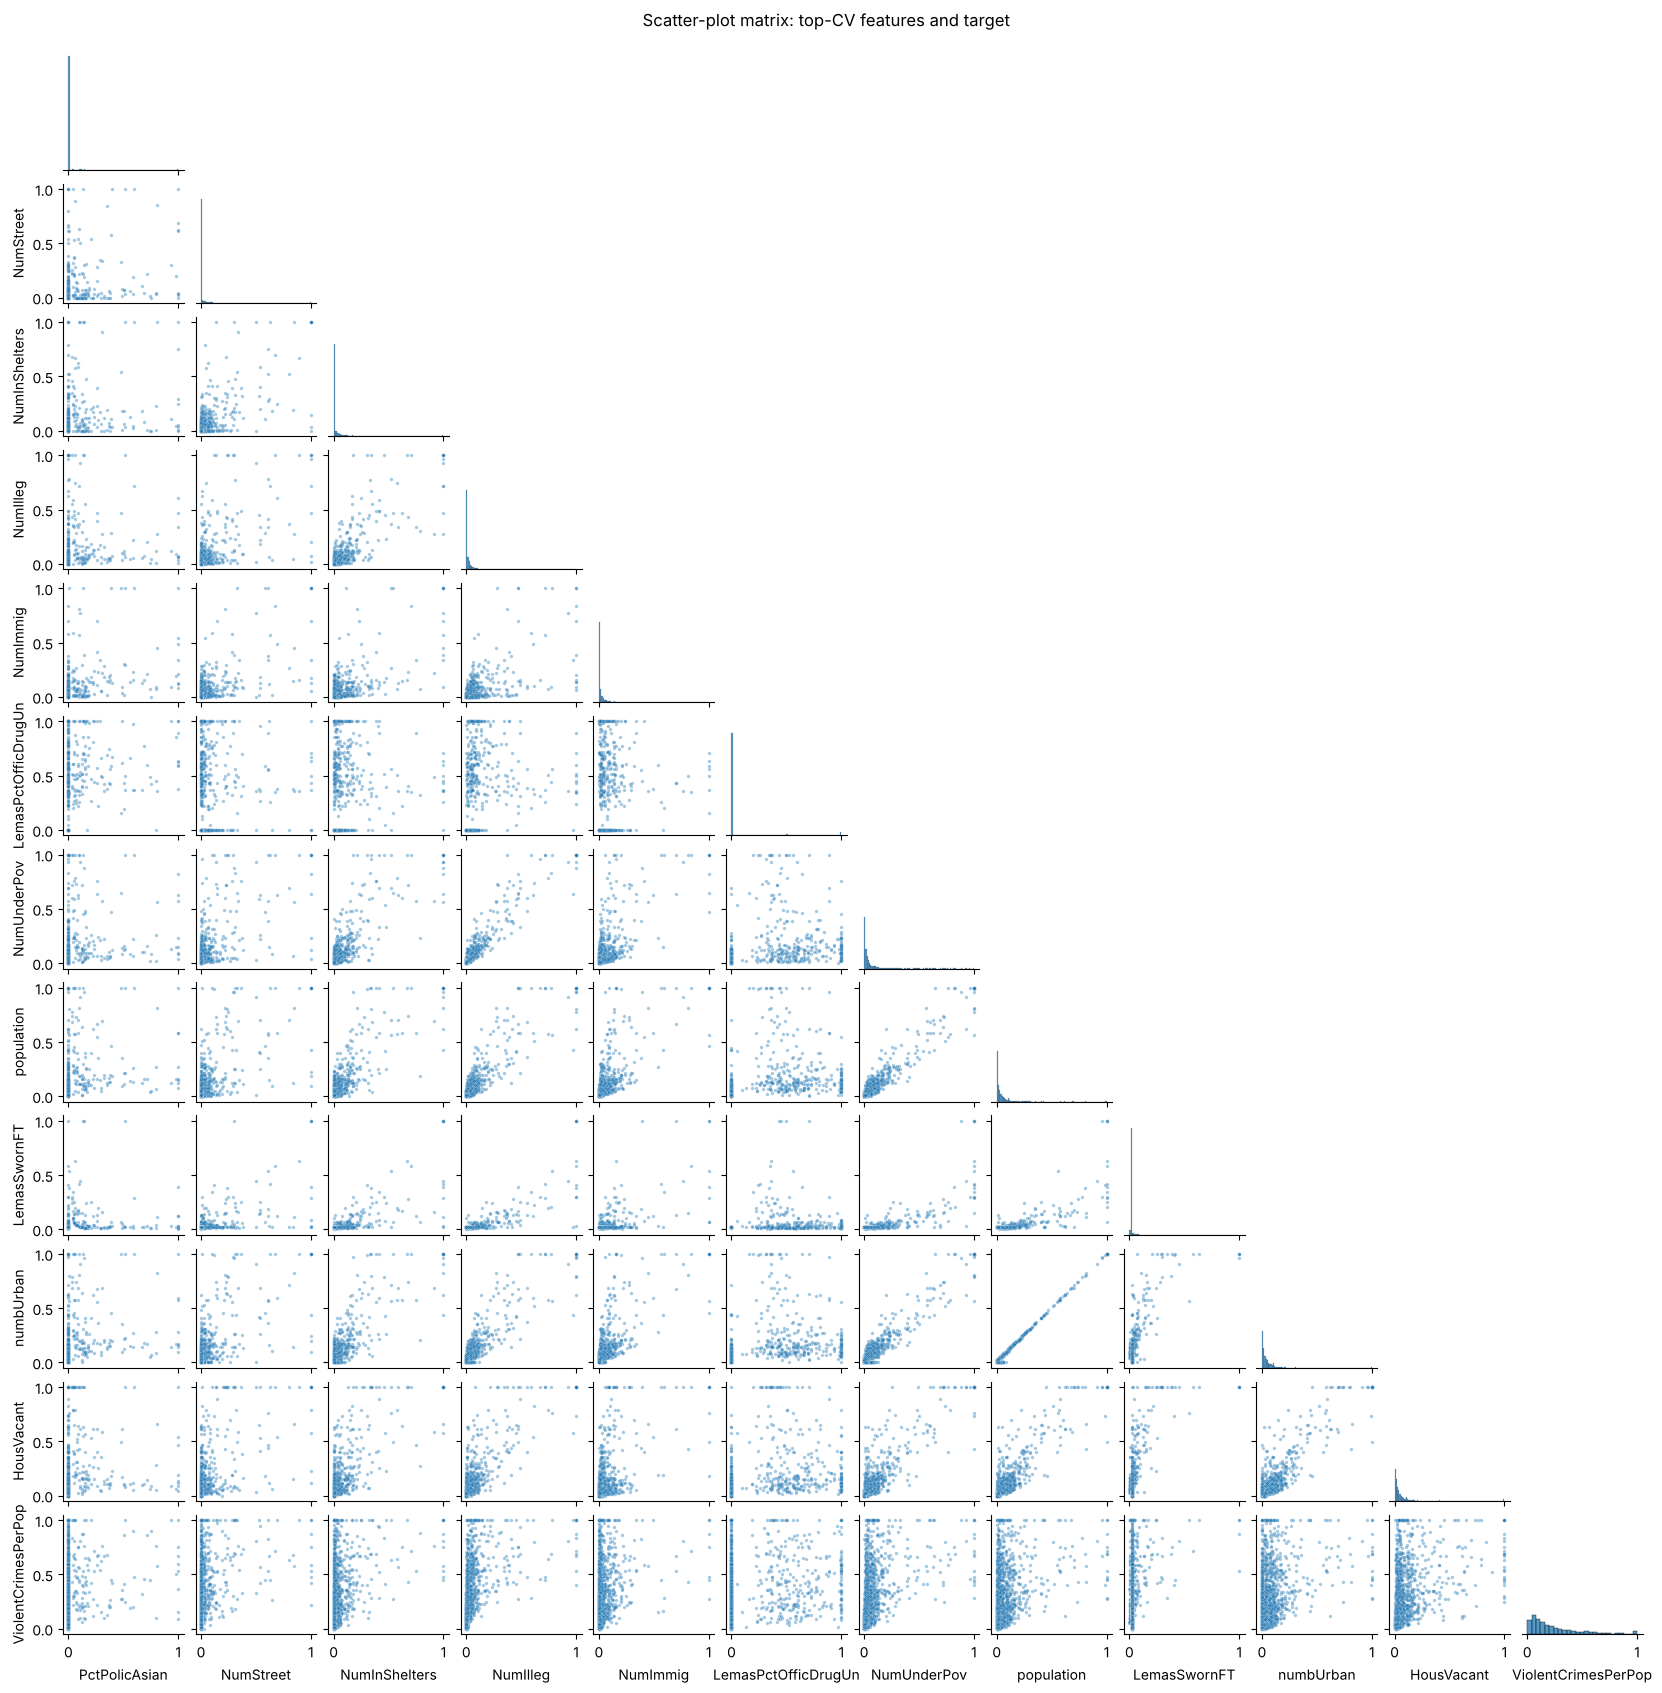

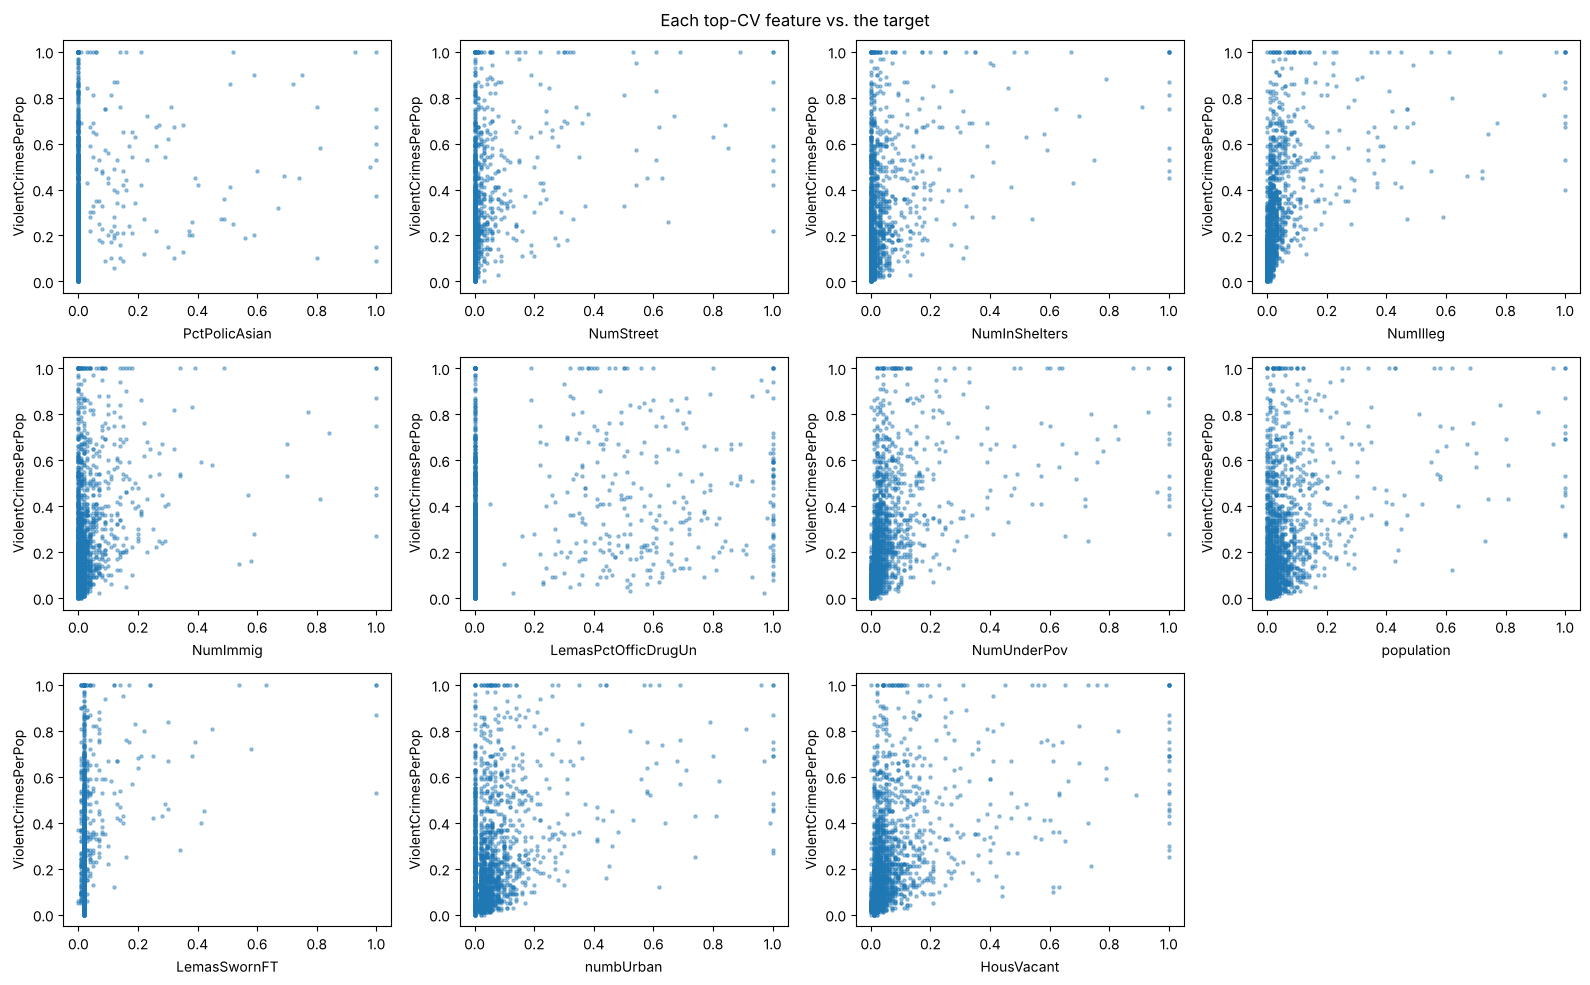

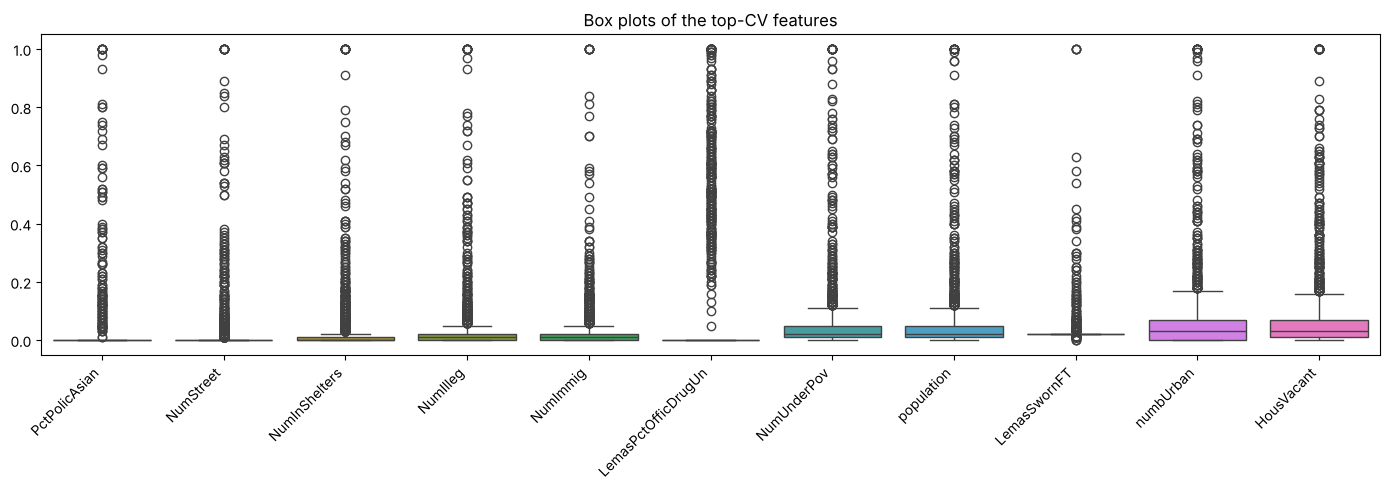

,corr with target,skewness,% at median value,% box-plot outliers,|corr| rank among 122
PctPolicAsian,0.204,7.295,93.480,6.520,78
NumStreet,0.340,7.020,80.090,19.910,37
NumInShelters,0.376,6.740,63.190,19.860,30
NumIlleg,0.471,6.273,27.232,12.387,20
NumImmig,0.294,7.472,24.875,12.287,50
LemasPctOfficDrugUn,0.349,2.554,84.504,15.496,36
NumUnderPov,0.448,5.181,15.697,9.829,23
population,0.367,5.064,13.591,10.933,31
LemasSwornFT,0.273,12.025,88.014,11.986,58
numbUrban,0.363,4.840,9.679,6.820,33


In [14]:
k = int(np.floor(np.sqrt(128)))
top = cv_vals.index[:k].tolist()
print("k =", k)
display(describe_vars(top, cv_vals.rename("CV").round(3)))
full_top = X_all[top].copy(); full_top[target] = np.r_[ytr, yte]
g = sns.pairplot(full_top, plot_kws={"s": 6, "alpha": 0.4}, corner=True, height=1.4)
g.fig.suptitle("Scatter-plot matrix: top-CV features and target", y=1.01); plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), top):
    ax.scatter(full_top[c], full_top[target], s=5, alpha=0.4)
    ax.set_xlabel(c); ax.set_ylabel(target)
axes.ravel()[-1].axis("off")
plt.suptitle("Each top-CV feature vs. the target"); plt.tight_layout(); plt.show()

plt.figure(figsize=(14, 5))
sns.boxplot(data=full_top[top]); plt.xticks(rotation=45, ha="right")
plt.title("Box plots of the top-CV features"); plt.tight_layout(); plt.show()

# numbers behind the plots
q1_, q3_ = full_top[top].quantile(.25), full_top[top].quantile(.75)
outl = ((full_top[top] > q3_ + 1.5 * (q3_ - q1_)) | (full_top[top] < q1_ - 1.5 * (q3_ - q1_))).mean()
evid = pd.DataFrame({"corr with target": full_top[top].corrwith(full_top[target]),
                     "skewness": full_top[top].skew(),
                     "% at median value": [100 * (full_top[c] == full_top[c].median()).mean() for c in top],
                     "% box-plot outliers": 100 * outl})
evid["|corr| rank among 122"] = [int((tc.abs() >= abs(tc[c])).sum()) for c in top]
display(evid.round(3))

**Can we draw conclusions about significance from the scatter plots?** No, and the numbers next to the plots show why. (1) **The 11 highest-CV features are not the most predictive.** Their correlation with the target ranks between 20th and 78th out of 122, and the strongest of them, `NumIlleg` with r = 0.47, is far below `PctKids2Par` and `PctIlleg` (|r| = 0.74). (2) **The plots are dominated by skew and outliers.** Skewness is 2.6 to 12.0 for every one of these features, and 7–20% of points are box-plot outliers. Most points pile up in a vertical stripe near 0, and in that stripe the target spans its whole range from 0 to 1. For the three police variables in the list, 84–93% of points sit at a single value. (3) **A scatter plot only shows a marginal, pairwise association.** It cannot account for the other 121 strongly correlated features, and it gives no standard error or p-value. For example, `population`, `numbUrban` and `NumUnderPov` all look like they trend upward with crime, yet LASSO in part (h) drops all three (and two of the police variables) once the other features are in the model, because they duplicate information already carried by other features. Significance has to be judged from a fitted model (t-tests, confidence intervals, or whether a regularized model keeps the variable), not by eye from these plots.

### (f) Linear regression (least squares)

In [15]:
ols = LinearRegression().fit(Xtr, ytr)
mse_ols = mean_squared_error(yte, ols.predict(Xte))
print(f"OLS test MSE = {mse_ols:.5f}")
results = {"Least squares": mse_ols}

OLS test MSE = 0.01797


### (g) Ridge regression, λ by 10‑fold CV

In [16]:
kf = KFold(n_splits=10, shuffle=True, random_state=RS)
ridge_alphas = np.logspace(-3, 3, 100)
ridge = RidgeCV(alphas=ridge_alphas, cv=kf, scoring="neg_mean_squared_error").fit(Xtr, ytr)
mse_ridge = mean_squared_error(yte, ridge.predict(Xte))
print(f"best lambda = {ridge.alpha_:.4f}; ridge test MSE = {mse_ridge:.5f}")
results["Ridge"] = mse_ridge

best lambda = 2.1544; ridge test MSE = 0.01753


### (h) LASSO, λ by 10‑fold CV — raw features, then standardized features

In [17]:
lasso = LassoCV(alphas=200, cv=kf, random_state=RS, max_iter=100000).fit(Xtr, ytr)
mse_lasso = mean_squared_error(yte, lasso.predict(Xte))
sel = pd.Series(lasso.coef_, index=feats)
sel = sel[sel != 0].sort_values(key=np.abs, ascending=False)
print(f"best lambda = {lasso.alpha_:.6f}; LASSO test MSE = {mse_lasso:.5f}; selected {len(sel)} of {len(feats)} features")
print("All selected variables, sorted by |coefficient|, with their meaning:")
display(describe_vars(sel.index, sel.rename("coefficient").round(4)))
print("Dropped (coefficient = 0):", sorted(set(feats) - set(sel.index)))
results["LASSO (raw)"] = mse_lasso

best lambda = 0.000082; LASSO test MSE = 0.01769; selected 79 of 122 features
All selected variables, sorted by |coefficient|, with their meaning:


,coefficient,meaning
agePct12t29,-0.3208,percentage of population that is 12-29 in age
racepctblack,0.2698,percentage of population that is african american
PctPersDenseHous,0.2384,percent of persons in dense housing (more than 1 person per room)
PctKids2Par,-0.2014,percentage of kids in family housing with two parents
MedRent,0.1830,median gross rent (Census variable H43A from file STF3A - includes utilities)
PctEmploy,0.1759,percentage of people 16 and over who are employed
MalePctNevMarr,0.1726,percentage of males who have never married
RentLowQ,-0.1715,rental housing - lower quartile rent
NumStreet,0.1639,number of homeless people counted in the street
PctPopUnderPov,-0.1602,percentage of people under the poverty level


Dropped (coefficient = 0): ['LemasPctOfficDrugUn', 'LemasSwFTFieldOps', 'LemasSwFTPerPop', 'LemasSwornFT', 'LemasTotReqPerPop', 'NumUnderPov', 'OwnOccHiQuart', 'OwnOccMedVal', 'PctBornSameState', 'PctEmplProfServ', 'PctFam2Par', 'PctHousOwnOcc', 'PctImmigRec5', 'PctImmigRec8', 'PctImmigRecent', 'PctLargHouseFam', 'PctNotHSGrad', 'PctOccupMgmtProf', 'PctPolicMinor', 'PctPolicWhite', 'PctRecImmig5', 'PctRecImmig8', 'PctRecentImmig', 'PctSameHouse85', 'PctSameState85', 'PctSpeakEnglOnly', 'PctUnemployed', 'PersPerFam', 'PersPerRentOccHous', 'PolicBudgPerPop', 'PolicOperBudg', 'PolicPerPop', 'RentHighQ', 'RentMedian', 'TotalPctDiv', 'agePct16t24', 'householdsize', 'medIncome', 'numbUrban', 'perCapInc', 'population', 'racePctHisp', 'racePctWhite']


In [18]:
lasso_std = make_pipeline(StandardScaler(),
                          LassoCV(alphas=200, cv=kf, random_state=RS, max_iter=100000)).fit(Xtr, ytr)
lcv = lasso_std[-1]
mse_lasso_std = mean_squared_error(yte, lasso_std.predict(Xte))
sel_std = pd.Series(lcv.coef_, index=feats)
sel_std = sel_std[sel_std != 0].sort_values(key=np.abs, ascending=False)
print(f"best lambda = {lcv.alpha_:.6f}; standardized LASSO test MSE = {mse_lasso_std:.5f}; selected {len(sel_std)} of {len(feats)} features")
print("All selected variables (standardized fit), sorted by |coefficient|, with their meaning:")
display(describe_vars(sel_std.index, sel_std.rename("coefficient (per 1 SD)").round(4)))
results["LASSO (standardized)"] = mse_lasso_std
both = set(sel.index) & set(sel_std.index)
print(f"selected in both: {len(both)} | only raw: {sorted(set(sel.index) - both)} | only standardized: {sorted(set(sel_std.index) - both)}")
print("Feature std range (why standardization changes little):",
      round(Xtr.std().min(), 3), "to", round(Xtr.std().max(), 3), "| all features lie in [",
      Xtr.min().min(), ",", Xtr.max().max(), "]")

best lambda = 0.000637; standardized LASSO test MSE = 0.01772; selected 76 of 122 features
All selected variables (standardized fit), sorted by |coefficient|, with their meaning:


,coefficient (per 1 SD),meaning
racepctblack,0.0680,percentage of population that is african american
PctPersDenseHous,0.0432,percent of persons in dense housing (more than 1 person per room)
agePct12t29,-0.0431,percentage of population that is 12-29 in age
PctKids2Par,-0.0406,percentage of kids in family housing with two parents
RentLowQ,-0.0307,rental housing - lower quartile rent
MedRent,0.0303,median gross rent (Census variable H43A from file STF3A - includes utilities)
PctPopUnderPov,-0.0293,percentage of people under the poverty level
PctEmploy,0.0250,percentage of people 16 and over who are employed
MalePctNevMarr,0.0245,percentage of males who have never married
PctIlleg,0.0240,percentage of kids born to never married


selected in both: 75 | only raw: ['PctBSorMore', 'PctWorkMomYoungKids', 'agePct65up', 'medFamInc'] | only standardized: ['PctImmigRecent']
Feature std range (why standardization changes little): 0.054 to 0.446 | all features lie in [ 0.0 , 1.0 ]


**Comparison.** With the raw features, LASSO chooses λ ≈ 8.2e-5 and keeps 79 of 122 features (test MSE 0.01769). With standardized features it chooses λ ≈ 6.4e-4 and keeps 76 features (test MSE 0.01772). The two test errors differ by less than 0.2%, and the selected sets overlap in 75 variables: only 4 weak features are kept by the raw fit alone and 1 by the standardized fit alone. The reason, printed above, is that all features already lie in [0, 1] and their standard deviations only range from 0.05 to 0.45, so standardizing changes their relative scale by at most a factor of about 8 rather than reconciling very different units. Standardization does change the scale of λ, and it makes the coefficients comparable as effects per standard deviation: in that version `racepctblack`, `PctPersDenseHous` (crowded housing), `agePct12t29` (share aged 12–29), `PctKids2Par` and rent levels have the largest effects. The variables LASSO removes are mostly redundant ones identified in part (c): duplicate police per-capita measures, the overlapping immigration windows, the house-value quartiles, and size counts such as `population`. Both LASSO fits improve slightly on least squares (0.01797) while using about 35% fewer variables.

### (i) Principal components regression, M by 10‑fold CV

best M = 96; PCR test MSE = 0.01834


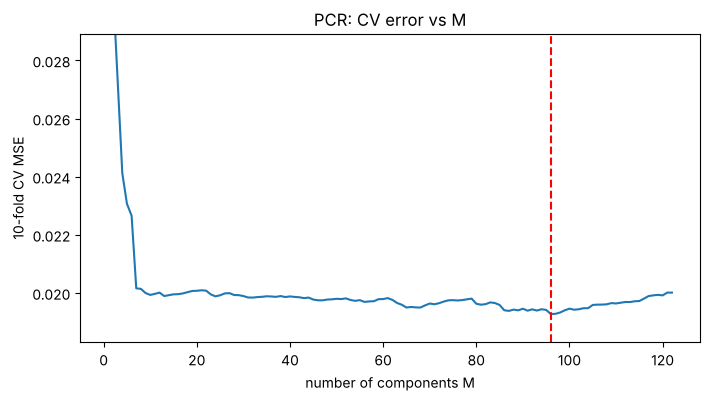

M =   5: 63.7% of feature variance, CV MSE = 0.02307
M =  10: 77.5% of feature variance, CV MSE = 0.01993
M =  20: 87.4% of feature variance, CV MSE = 0.02007
M =  96: 99.9% of feature variance, CV MSE = 0.01927


In [19]:
pcr = Pipeline([("pca", PCA()), ("lr", LinearRegression())])
gs_pcr = GridSearchCV(pcr, {"pca__n_components": range(1, len(feats) + 1)},
                      cv=kf, scoring="neg_mean_squared_error").fit(Xtr, ytr)
M = gs_pcr.best_params_["pca__n_components"]
mse_pcr = mean_squared_error(yte, gs_pcr.predict(Xte))
print(f"best M = {M}; PCR test MSE = {mse_pcr:.5f}")
cvm = -gs_pcr.cv_results_["mean_test_score"]
plt.figure(figsize=(8, 4)); plt.plot(range(1, len(feats)+1), cvm); plt.axvline(M, ls="--", c="r")
plt.xlabel("number of components M"); plt.ylabel("10-fold CV MSE"); plt.ylim(cvm.min()*0.95, cvm.min()*1.5)
plt.title("PCR: CV error vs M"); plt.show()
results["PCR"] = mse_pcr
evr = np.cumsum(PCA().fit(Xtr).explained_variance_ratio_)
for m_ in [5, 10, 20, M]:
    print(f"M = {m_:3d}: {100*evr[m_-1]:.1f}% of feature variance, CV MSE = {cvm[m_-1]:.5f}")

**Interpretation.** The CV curve, together with the printed explained variance, shows that a few components are not enough. The first 10 components explain 77.5% of the feature variance but give a CV MSE of 0.0199. CV keeps improving slowly and is minimized at M = 96, where 99.9% of the variance is explained (CV MSE 0.0193). At that point PCR is close to full least squares on 122 features. PCR is the worst of the linear models on the test set (0.01834). The reason is that PCA chooses directions of maximum *feature* variance without looking at the target, and the high-variance directions here are partly driven by skewed counts and imputed police variables rather than by the family-structure variables that predict crime.

### (j) L1‑penalized gradient boosting tree (XGBoost), α by CV
In XGBoost, `reg_alpha` is the L1 penalty on the leaf weights of each tree. The other hyper‑parameters also need
values, so rather than fixing them by hand I tune them in two CV stages, with the same 10 folds:

1. **Stage 1:** tree depth, learning rate and number of trees, with α = 0.
2. **Stage 2:** α on a log grid, with the stage‑1 settings fixed. This is the regularization parameter the question asks for.

In [20]:
stage1 = GridSearchCV(
    xgb.XGBRegressor(subsample=0.8, colsample_bytree=0.8, objective="reg:squarederror", random_state=RS, n_jobs=-1),
    {"max_depth": [2, 3, 4, 6], "learning_rate": [0.03, 0.1], "n_estimators": [200, 500]},
    cv=kf, scoring="neg_mean_squared_error").fit(Xtr, ytr)
s1 = pd.DataFrame(stage1.cv_results_)[["param_max_depth", "param_learning_rate", "param_n_estimators", "mean_test_score", "std_test_score"]]
s1["CV MSE"] = -s1.pop("mean_test_score"); s1["CV MSE sd"] = s1.pop("std_test_score")
print("Stage 1 — all settings, sorted by CV MSE:")
display(s1.sort_values("CV MSE").round(5).reset_index(drop=True))
print("chosen:", stage1.best_params_)

Stage 1 — all settings, sorted by CV MSE:


,param_max_depth,param_learning_rate,param_n_estimators,CV MSE,CV MSE sd
0,3,0.03,500,0.01900,0.00286
1,4,0.03,500,0.01919,0.00304
2,3,0.10,200,0.01937,0.00312
3,3,0.03,200,0.01938,0.00335
4,4,0.03,200,0.01940,0.00340
5,6,0.03,500,0.01957,0.00322
6,6,0.10,200,0.01960,0.00311
7,6,0.10,500,0.01960,0.00310
8,6,0.03,200,0.01961,0.00337
9,2,0.03,500,0.01963,0.00309


chosen: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 500}


best alpha = 0.0002154; XGBoost test MSE = 0.01594


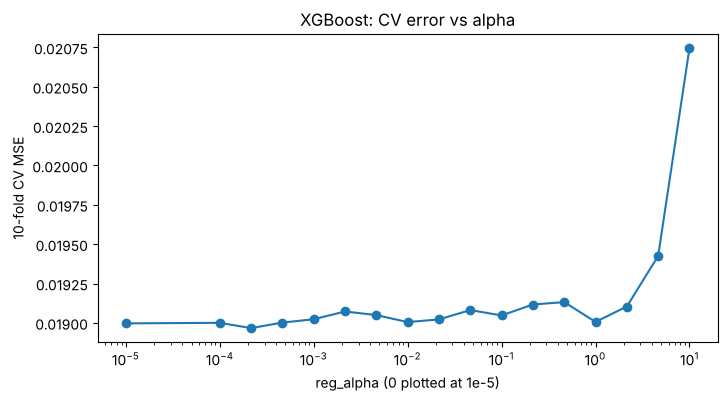

,reg_alpha,CV MSE,CV MSE sd
0,0.00000,0.01900,0.00286
1,0.00010,0.01900,0.00286
2,0.00022,0.01897,0.00288
3,0.00046,0.01900,0.00281
4,0.00100,0.01902,0.00279
5,0.00215,0.01907,0.00295
6,0.00464,0.01905,0.00293
7,0.01000,0.01900,0.00294
8,0.02154,0.01902,0.00303
9,0.04642,0.01908,0.00289


Top-10 features by XGBoost importance (gain), with their meaning:


,importance,meaning
PctIlleg,0.1600,percentage of kids born to never married
PctKids2Par,0.1217,percentage of kids in family housing with two parents
NumIlleg,0.0536,number of kids born to never married
racePctWhite,0.0346,percentage of population that is caucasian
PctFam2Par,0.0337,percentage of families (with kids) that are headed by two parents
numbUrban,0.0202,number of people living in areas classified as urban
PctPersDenseHous,0.0199,percent of persons in dense housing (more than 1 person per room)
FemalePctDiv,0.0152,percentage of females who are divorced
NumStreet,0.0145,number of homeless people counted in the street
TotalPctDiv,0.0140,percentage of population who are divorced


In [21]:
xgb_base = xgb.XGBRegressor(**stage1.best_params_, subsample=0.8, colsample_bytree=0.8,
                            objective="reg:squarederror", random_state=RS, n_jobs=-1)
alpha_grid = np.r_[0, np.logspace(-4, 1, 16)]
gs_xgb = GridSearchCV(xgb_base, {"reg_alpha": alpha_grid}, cv=kf,
                      scoring="neg_mean_squared_error", n_jobs=1).fit(Xtr, ytr)
a_best = gs_xgb.best_params_["reg_alpha"]
mse_xgb = mean_squared_error(yte, gs_xgb.predict(Xte))
print(f"best alpha = {a_best:.4g}; XGBoost test MSE = {mse_xgb:.5f}")
plt.figure(figsize=(8, 4))
plt.semilogx(np.where(alpha_grid == 0, 1e-5, alpha_grid), -gs_xgb.cv_results_["mean_test_score"], marker="o")
plt.xlabel("reg_alpha (0 plotted at 1e-5)"); plt.ylabel("10-fold CV MSE"); plt.title("XGBoost: CV error vs alpha"); plt.show()
results["XGBoost (L1)"] = mse_xgb

s2 = pd.DataFrame({"reg_alpha": alpha_grid, "CV MSE": -gs_xgb.cv_results_["mean_test_score"],
                   "CV MSE sd": gs_xgb.cv_results_["std_test_score"]})
display(s2.round(5))

imp_x = pd.Series(gs_xgb.best_estimator_.feature_importances_, index=feats).sort_values(ascending=False).head(10)
print("Top-10 features by XGBoost importance (gain), with their meaning:")
display(describe_vars(imp_x.index, imp_x.rename("importance").round(4)))

**Interpretation.** **Stage 1:** depth 3, learning rate 0.03 and 500 trees gives the lowest CV MSE (0.01900). The 16 settings span only 0.0190–0.0200, all within about one fold standard deviation (≈ 0.003), so the model is not very sensitive to these choices. Shallow trees (depth 3–4) with a small learning rate do slightly better than depth 6, which fits a data set of only 1,495 rows. **Stage 2:** the CV curve for α is essentially flat from 0 to about 2 (CV MSE 0.01897–0.01913). It rises only for α ≥ 4.6 (0.0194) and α = 10 (0.0208), where the L1 penalty starts shrinking leaf weights too much. The minimum is at **α ≈ 2.2e-4**. Because the differences for α ≤ 2 are far smaller than the fold-to-fold standard deviation, CV cannot really tell these values apart; any α in that range would give a very similar model. The tuned model has the lowest test error of all methods (MSE 0.01594). Its most important features are again the family-structure variables (`PctIlleg`, `PctKids2Par`, `NumIlleg`, `PctFam2Par`), matching the strongest correlations found in part (c).

### Summary of test errors

In [22]:
summary = pd.Series(results, name="test MSE").to_frame()
summary["test RMSE"] = np.sqrt(summary["test MSE"])
summary.round(5)

,test MSE,test RMSE
Least squares,0.01797,0.13404
Ridge,0.01753,0.13238
LASSO (raw),0.01769,0.13300
LASSO (standardized),0.01772,0.13312
PCR,0.01834,0.13542
XGBoost (L1),0.01594,0.12624


**Conclusion.** All linear models perform similarly (test MSE 0.0175–0.0183). Regularization (ridge, LASSO) gives a small improvement over plain least squares, which is consistent with the strong multicollinearity in part (c). PCR is slightly worse because its components are chosen without looking at the response. The L1-penalized XGBoost model has the lowest test error (MSE 0.01594, about 11% lower than least squares), which suggests nonlinear effects and interactions that the linear models miss. All test errors come from a single 1495/499 split, so small differences, such as those between ridge and the two LASSO fits, should not be over-interpreted.